# 🗓️ Horario RL — Multi-trabajador

## Acciones
| Acción | Significado   | Slots |
|--------|--------------|-------|
| 0      | No trabaja   | 1     |
| 1      | Pausa Activa | 1     |
| 2      | Almuerzo     | 6     |
| 3      | Trabaja      | 1     |

## Reglas implementadas
| # | Regla |
|---|-------|
| R1 | Mín. 1h (4 slots) de trabajo continuo antes de Pausa/Almuerzo |
| R2 | Máx. 2h (8 slots) de trabajo continuo sin Pausa |
| R3 | Jornada = 32 slots (Trabaja + Pausa). Almuerzo = 6 slots, NO cuenta en jornada |
| R4 | Horario continuo: `No trabaja` solo al inicio o al final |
| R5 | Último estado activo = `Trabaja` |
| R6 | Al menos 1 empleado trabajando por franja (cobertura mínima) |

## Objetivo de cobertura
Minimizar `|oferta - demanda|` por slot al final del episodio.
- **Déficit** (oferta < demanda): penalización × 1.5 por slot·trabajador
- **Exceso** (oferta > demanda): penalización × 0.5 por slot·trabajador


In [ ]:
from typing import Optional
from sb3_contrib import MaskablePPO
from sb3_contrib.common.wrappers import ActionMasker
import numpy as np
import pandas as pd
import gymnasium as gym
from gymnasium import spaces
from validar import validar_multi, cargar_demanda
from Pruebas.entorno import HorarioMultiEnv
from visualizar import mostrar_horario
from acciones import configurar_jornada
from entorno import *

In [3]:
DEMANDA_REAL = cargar_demanda('Datos/Demanda.csv')
print("Demanda:", DEMANDA_REAL)
print("Min:", DEMANDA_REAL.min(), "| Max:", DEMANDA_REAL.max())

Demanda: [ 2  2  4  7  8  8  9  8  6  8  9  9  9 12 16 16 16 13 12 11 13 14 10  9
  9 11  8  9 10  8  9  9  5  5  4  6  8  4  5  1  3  2  2  2  2  2]
Min: 1 | Max: 16


In [ ]:
M, K = 8, None      # K=None desactiva la regla
print("K mínimo para M =", M, ":", k_minimo(M))

def mask_fn(env):
    mask = np.zeros(N_ACTIONS, dtype=bool)
    for a in env.unwrapped._acciones_validas():
        mask[a] = True
    return mask

def make_env():
    return ActionMasker(HorarioMultiEnv(num_trabajadores=M, demanda=DEMANDA_REAL,
                                         max_almorzando=K), mask_fn)

model = MaskablePPO("MultiInputPolicy", make_env(), verbose=1,
                    n_steps=2048, batch_size=256, n_epochs=10, learning_rate=3e-4,
                    gamma=1.0, ent_coef=0.01, seed=0,
                    policy_kwargs=dict(net_arch=dict(pi=[256, 256], vf=[256, 256])))
model.learn(total_timesteps=400_000)
model.save("Pesos/horario_V4_W8")

In [4]:
M, K = 8, None 


def mask_fn(env):
    mask = np.zeros(N_ACTIONS, dtype=bool)
    for a in env.unwrapped._acciones_validas():
        mask[a] = True
    return mask

def make_env():
    return ActionMasker(HorarioMultiEnv(num_trabajadores=M, demanda=DEMANDA_REAL,
                                         max_almorzando=K), mask_fn)
# ── Evaluación del modelo entrenado ──────────────────────────────────────────
# Descomenta tras el entrenamiento
model = MaskablePPO.load("Pesos/horario_V4_W8")

env_eval = HorarioMultiEnv(num_trabajadores=M, demanda=DEMANDA_REAL)
obs, info = env_eval.reset(seed=0)
done = False
while not done:
    mask = mask_fn(env_eval)
    action, _ = model.predict(obs, action_masks=mask, deterministic=True)
    obs, reward, done, _, info = env_eval.step(int(action))

env_eval.render()
validar_multi(env_eval.horarios, DEMANDA_REAL)

print("Descomenta el bloque para evaluar el modelo entrenado")


── Validación multi-trabajador ────────────────
  ✅ W1: jornada=True alm=True cont=True R5=True R1=True R2=True
  ✅ W2: jornada=True alm=True cont=True R5=True R1=True R2=True
  ✅ W3: jornada=True alm=True cont=True R5=True R1=True R2=True
  ✅ W4: jornada=True alm=True cont=True R5=True R1=True R2=True
  ✅ W5: jornada=True alm=True cont=True R5=True R1=True R2=True
  ✅ W6: jornada=True alm=True cont=True R5=True R1=True R2=True
  ✅ W7: jornada=True alm=True cont=True R5=True R1=True R2=True
  ✅ W8: jornada=True alm=True cont=True R5=True R1=True R2=True

  📊 Cobertura (oferta vs demanda):
     MAE         : 3.28 trabajadores/slot
     Déficit     : 135 slot·trabajador
     Exceso      : 16 slot·trabajador
     Slots exactos: 9/46
  ✅ R6 cobertura mínima (≥1 trabajando siempre): True
────────────────────────────────────────────────
Descomenta el bloque para evaluar el modelo entrenado


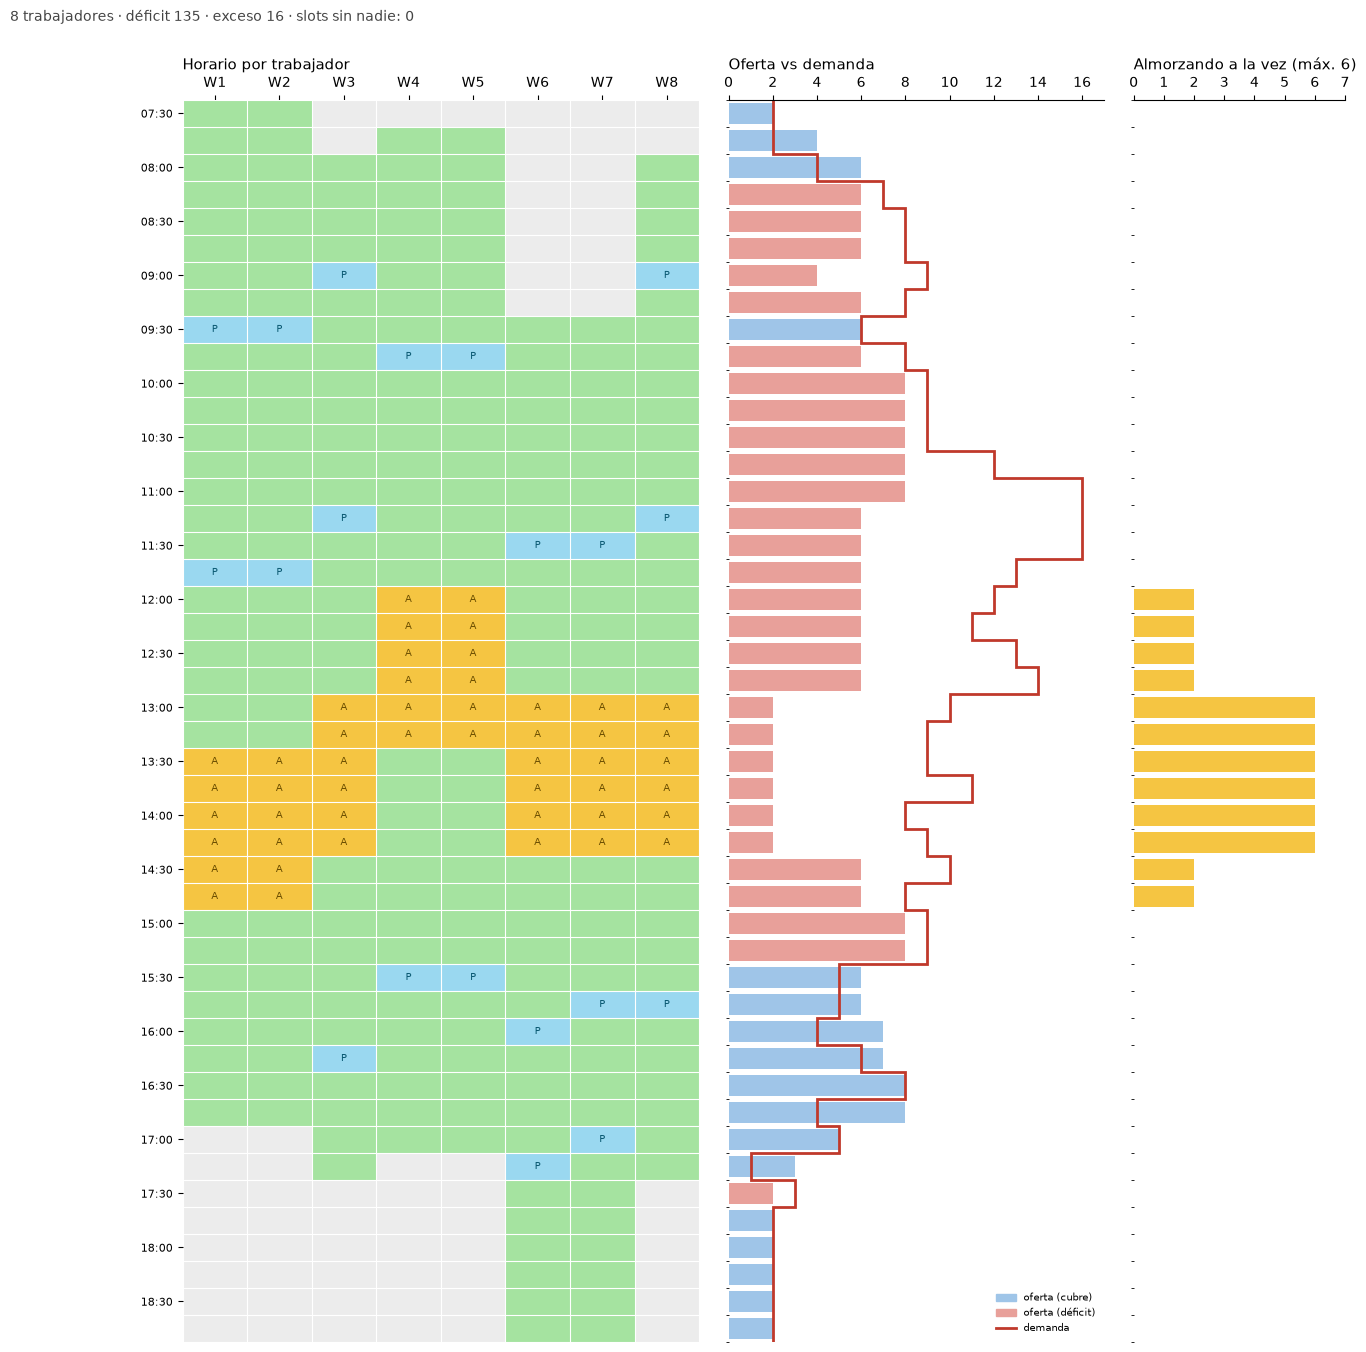

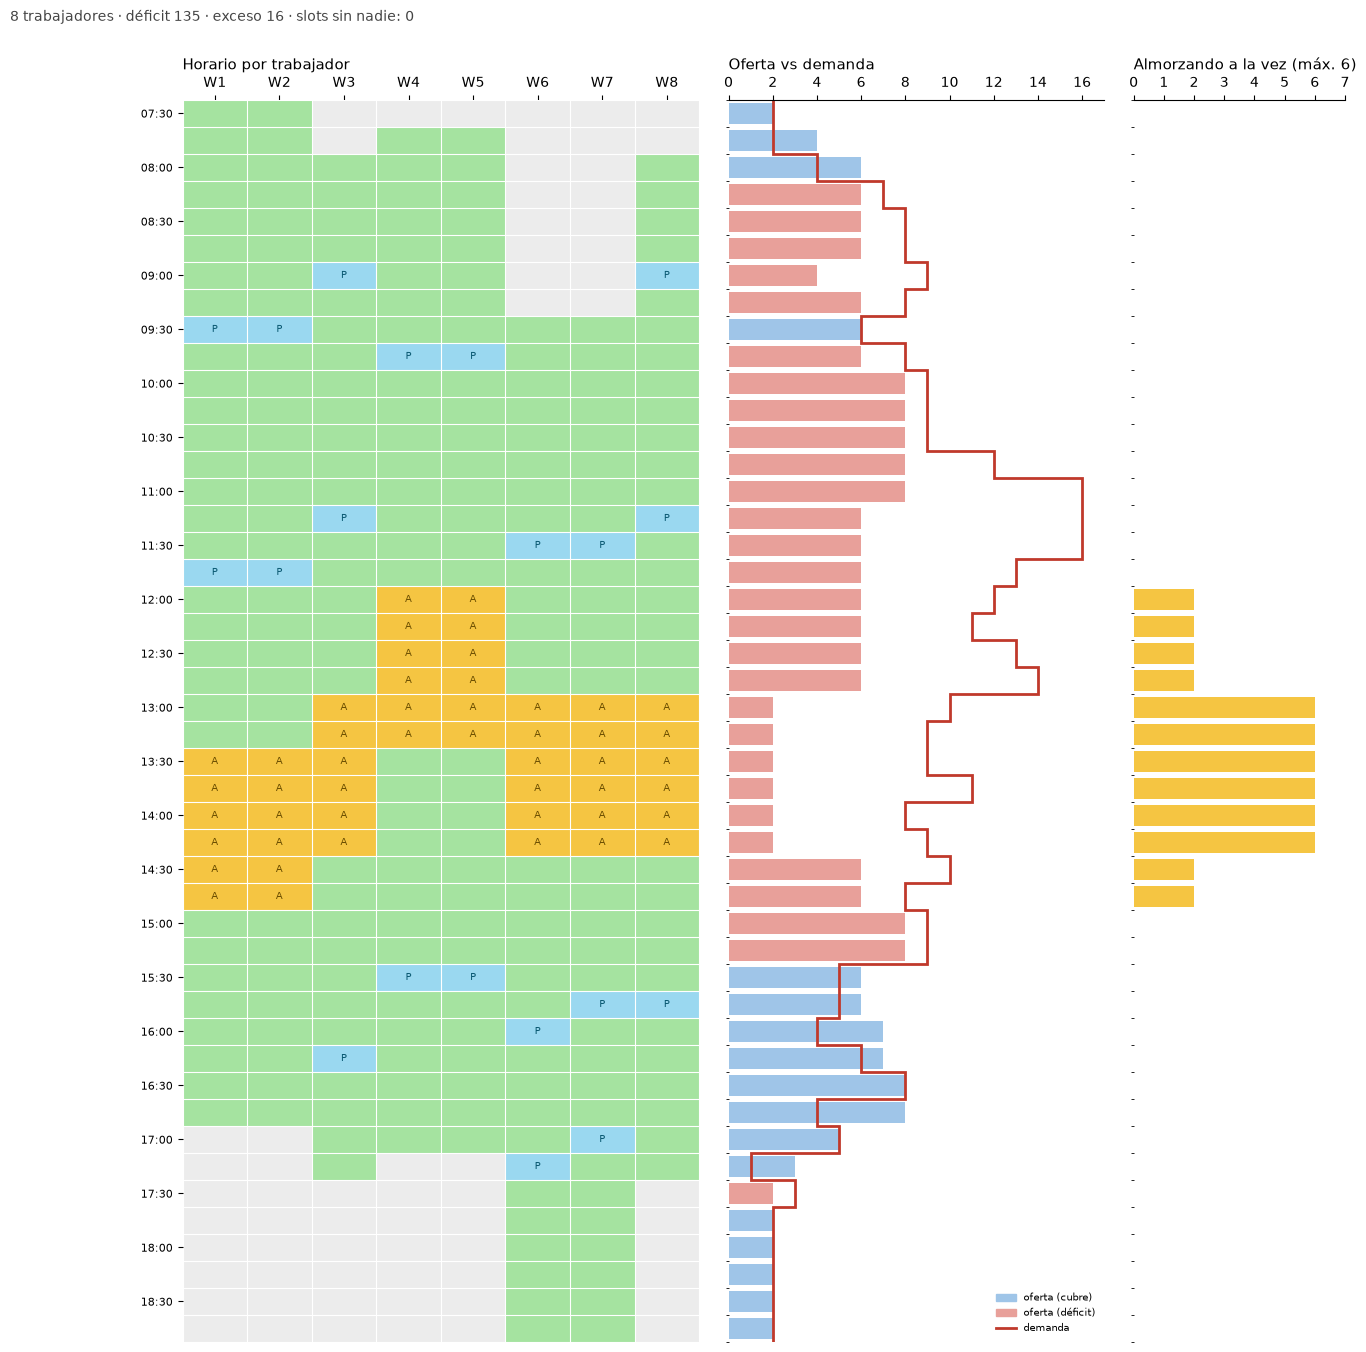

In [ ]:
mostrar_horario(env_eval.horarios, DEMANDA_REAL, K=K)   # K=None si no usas la regla

In [7]:
config=configurar_jornada()
TRABAJA=config['TRABAJA']
print("oferta:", (env_eval.horarios == TRABAJA).sum(axis=0).tolist())

oferta: [2, 4, 6, 6, 6, 6, 4, 6, 6, 6, 8, 8, 8, 8, 8, 6, 6, 6, 6, 6, 6, 6, 2, 2, 2, 2, 2, 2, 6, 6, 8, 8, 6, 6, 7, 7, 8, 8, 5, 3, 2, 2, 2, 2, 2, 2]


In [8]:
oferta=(env_eval.horarios == TRABAJA).sum(axis=0).tolist()

resultado = np.abs(DEMANDA_REAL - oferta)

# Sumar todos los valores del vector resultante
suma_total = np.sum(resultado)

print("Vector resultante:", resultado)
print("Suma total:", suma_total)

Vector resultante: [ 0  2  2  1  2  2  5  2  0  2  1  1  1  4  8 10 10  7  6  5  7  8  8  7
  7  9  6  7  4  2  1  1  1  1  3  1  0  4  0  2  1  0  0  0  0  0]
Suma total: 151
